# LightGBM (gradient boosting)
### Tesis de Maestría · Modelo de Valuación Automática (AVM) · Distrito Centro (Rosario)

## Marco teórico

El Random Forest (notebook 03) promedia muchos árboles **independientes** para bajar la varianza
(*bagging*). El **gradient boosting** (Friedman, 2001) sigue la idea opuesta y complementaria:
construye los árboles de forma **secuencial**, y cada árbol nuevo se entrena para **corregir los errores
residuales** del conjunto anterior. En lugar de promediar modelos fuertes e independientes, suma muchos
modelos **débiles** (árboles chicos) que, guiados por el gradiente de la función de pérdida, van
reduciendo el sesgo paso a paso (ESL, cap. 10; ISL, cap. 8). El aprendizaje se controla con la **tasa de
aprendizaje** (*learning rate*): pasos chicos y muchos árboles suelen generalizar mejor.

**LightGBM** (Ke et al., 2017) es una implementación moderna y eficiente de gradient boosting con dos
ideas que lo hacen rápido y preciso: discretiza los predictores en **histogramas** (en vez de evaluar
todos los cortes posibles) y hace crecer los árboles **por hoja** (*leaf-wise*, expandiendo la hoja que
más reduce la pérdida) en vez de por nivel. Además trae **regularización** incorporada —submuestreo de
filas y columnas, mínimo de casos por hoja, penalizaciones L1/L2— que, bien tuneada, **controla el
sobreajuste** que en un boosting sin frenos sería severo.

Cerramos con LightGBM la comparación de **RQ1**: hedónico (lineal) → Random Forest (bagging) → LightGBM
(boosting), todos sobre las mismas particiones. La expectativa teórica es que el boosting, al atacar el
**sesgo** de forma dirigida, iguale o supere al Random Forest (Kuhn & Johnson, 2013).

## Metodología (protocolo experimental)

- **Datos y target:** matriz de modelado; target $\log(1+\text{precio\_usd})$, métricas en USD.
- **Particionado:** mismas **particiones group-aware** (`GroupKFold`, 5 folds, grupo = `building_cluster_id`)
  que el hedónico y el RF → comparación **pareada** y sin fuga por republicaciones.
- **Preprocesamiento dentro del fold:** imputación + one-hot (mismo esquema que el RF, en igualdad de
  condiciones; LightGBM también maneja categóricas de forma nativa, pero mantenemos one-hot por
  comparabilidad).
- **CV anidada + búsqueda amplia:** en cada fold externo se elige el modelo por **búsqueda aleatoria**
  (`RandomizedSearchCV`, muchas combinaciones) con CV **interna** group-aware. La búsqueda aleatoria es
  más eficiente que la grilla en espacios de alta dimensión (Bergstra & Bengio, 2012). El test queda
  libre del sesgo por selección de hiperparámetros (ESL §7.10.2).
- **Reporte de train y test por escenario** (diagnóstico de sesgo–varianza) y **escenarios incrementales
  S1→S4**, como en los notebooks anteriores.

> **Nota de ejecución.** La búsqueda anidada entrena muchos modelos; correrlo completo lleva varios
> minutos. Es intencional: no limitamos la búsqueda por tiempo.

In [4]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from lightgbm import LGBMRegressor

ROOT = Path.cwd()
while not (ROOT / "data" / "processed").exists() and ROOT != ROOT.parent: ROOT = ROOT.parent
sns.set_theme(style="whitegrid", context="notebook")
PAL, PAL2, ACCENT, MOR = "#2c6e91", "#c0562b", "#3a8f5e", "#7b5ea7"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 12.5, "figure.autolayout": True})

df = pd.read_csv(ROOT / "data" / "processed" / "zonaprop_v2_matriz_modelado_centro.csv.gz")
y = np.log1p(pd.to_numeric(df["eda_precio_usd"], errors="coerce").values)
groups = df["building_cluster_id"].values
feat_cols = [c for c in df.columns if c.startswith("feat_")]

S1 = ["eda_superficie_total_m2","eda_superficie_cubierta_m2","eda_ambientes","eda_dormitorios",
      "eda_banos","eda_cocheras","eda_toilette","eda_antiguedad_anos","eda_antiguedad_estado",
      "eda_disposicion","eda_orientacion","eda_tipo_operacion","eda_expensas",
      "fe_ratio_cubierta_total","fe_sup_por_ambiente","fe_banos_por_ambiente",
      "fe_dormitorios_por_ambiente","fe_tiene_cochera","fe_expensas_informadas"]
S2 = ["barrio_oficial_geo","eda_latitud","eda_longitud"]
S3 = [c for c in ["fe_dist_centro_km","fe_dist_rio_km","fe_dist_espacio_verde_km","fe_dens_comercios_300m"] if c in df.columns]
escen = {"S1":[c for c in S1 if c in df.columns],
         "S2":[c for c in S1+S2 if c in df.columns],
         "S3":[c for c in S1+S2+S3 if c in df.columns],
         "S4":[c for c in S1+S2+S3 if c in df.columns]+feat_cols}
CAT = {"eda_antiguedad_estado","eda_disposicion","eda_orientacion","eda_tipo_operacion","barrio_oficial_geo"}
BIN = set(feat_cols) | {"fe_tiene_cochera","fe_expensas_informadas"}
SEED, N_IN, N_ITER = 42, 3, 60
DIST = {"m__n_estimators":randint(300,1400), "m__learning_rate":loguniform(0.01,0.15),
        "m__num_leaves":randint(15,90), "m__max_depth":randint(3,14), "m__min_child_samples":randint(5,70),
        "m__subsample":uniform(0.6,0.4), "m__colsample_bytree":uniform(0.6,0.4),
        "m__reg_lambda":loguniform(1e-3,20), "m__reg_alpha":loguniform(1e-3,20)}
print(f"Matriz: {len(df):,} avisos · {df['building_cluster_id'].nunique():,} grupos · LightGBM · CV anidada 5×{N_IN} · n_iter={N_ITER}")

Matriz: 4,765 avisos · 1,377 grupos · LightGBM · CV anidada 5×3 · n_iter=60


## Pipelines y esquema de evaluación

`nested` recorre los folds externos, busca los hiperparámetros de LightGBM **dentro** del train de cada
fold y devuelve métricas de **train** y **test** (y las OOF, para el análisis por segmento). Para la
comparación pareada evaluamos también el **hedónico (OLS)** y traemos los resultados del **Random Forest**
del notebook 03 (tabla `random_forest_s1_s4.csv`).

In [5]:
def prep_oh(cols):
    cat=[c for c in cols if c in CAT]; binz=[c for c in cols if c in BIN]; num=[c for c in cols if c not in cat and c not in binz]
    return ColumnTransformer([
        ("cat", Pipeline([("i",SimpleImputer(strategy="most_frequent")),("o",OneHotEncoder(handle_unknown="ignore",min_frequency=10,sparse_output=False))]), cat),
        ("bin", SimpleImputer(strategy="most_frequent"), binz),
        ("num", SimpleImputer(strategy="median"), num)], remainder="drop")

def prep_ols(cols):
    cat=[c for c in cols if c in CAT]; binz=[c for c in cols if c in BIN]; num=[c for c in cols if c not in cat and c not in binz]
    return ColumnTransformer([
        ("cat", Pipeline([("i",SimpleImputer(strategy="most_frequent")),("o",OneHotEncoder(handle_unknown="ignore",min_frequency=10))]), cat),
        ("bin","passthrough",binz),
        ("num", Pipeline([("i",SimpleImputer(strategy="median")),("s",StandardScaler())]), num)], remainder="drop")

def _met(yv,pv): return r2_score(yv,pv), np.sqrt(mean_squared_error(np.expm1(yv),np.expm1(pv)))

def lgbm(): return LGBMRegressor(random_state=SEED, n_jobs=1, subsample_freq=1, verbose=-1)

def nested(cols):
    "CV anidada LightGBM: búsqueda dentro del train de cada fold; devuelve train/test y OOF."
    gkf=GroupKFold(5); tr_r2=[];te_r2=[];tr_rm=[];te_rm=[];te_mape=[]; oof=np.full(len(y),np.nan)
    for tr,te in gkf.split(df,y,groups):
        base=Pipeline([("prep",prep_oh(cols)),("m",lgbm())])
        rs=RandomizedSearchCV(base,DIST,n_iter=N_ITER,cv=GroupKFold(N_IN),scoring="neg_mean_squared_error",random_state=SEED,n_jobs=-1).fit(df.iloc[tr][cols],y[tr],groups=groups[tr])
        est=rs.best_estimator_; ptr=est.predict(df.iloc[tr][cols]); pte=est.predict(df.iloc[te][cols]); oof[te]=pte
        a,b=_met(y[tr],ptr); c,d=_met(y[te],pte); tr_r2.append(a);tr_rm.append(b);te_r2.append(c);te_rm.append(d)
        ytu,ypu=np.expm1(y[te]),np.expm1(pte); te_mape.append(np.mean(np.abs((ytu-ypu)/ytu))*100)
    return dict(R2_train=np.mean(tr_r2),R2_test=np.mean(te_r2),R2_test_sd=np.std(te_r2),
                RMSE_train=np.mean(tr_rm),RMSE_test=np.mean(te_rm),MAPE_test=np.mean(te_mape),
                brecha=np.mean(tr_r2)-np.mean(te_r2)), oof

def ols_tt(cols):
    gkf=GroupKFold(5); tr=[];te=[];trm=[];tem=[];mp=[]; oof=np.full(len(y),np.nan)
    for a,b in gkf.split(df,y,groups):
        est=Pipeline([("p",prep_ols(cols)),("m",LinearRegression())]).fit(df.iloc[a][cols],y[a])
        pa,pb=est.predict(df.iloc[a][cols]),est.predict(df.iloc[b][cols]); oof[b]=pb
        r1,m1=_met(y[a],pa); r2,m2=_met(y[b],pb); tr.append(r1);trm.append(m1);te.append(r2);tem.append(m2)
        ytu,ypu=np.expm1(y[b]),np.expm1(pb); mp.append(np.mean(np.abs((ytu-ypu)/ytu))*100)
    return dict(R2_train=np.mean(tr),R2_test=np.mean(te),RMSE_train=np.mean(trm),RMSE_test=np.mean(tem),
                MAPE_test=np.mean(mp),brecha=np.mean(tr)-np.mean(te)), oof
print("Pipelines y utilitarios definidos.")

Pipelines y utilitarios definidos.


## 1. Entrenamiento vs. test por escenario (diagnóstico de sobreajuste)

Para cada escenario, R² y RMSE **en train y en test**, con la **brecha**. Como en el RF, la brecha lee el
sesgo–varianza; a diferencia del RF, la regularización que elige la búsqueda debería **achicar** esa
brecha.

,features,R2_train,R2_test,brecha_R2,RMSE_train,RMSE_test,MAPE_test
S1,19.0,0.907,0.864,0.043,36609.0,45448.0,20.1
S2,22.0,0.932,0.890,0.042,31516.0,42102.0,17.6
S3,26.0,0.936,0.889,0.047,30574.0,42388.0,17.6
S4,45.0,0.949,0.902,0.047,27047.0,40336.0,16.7


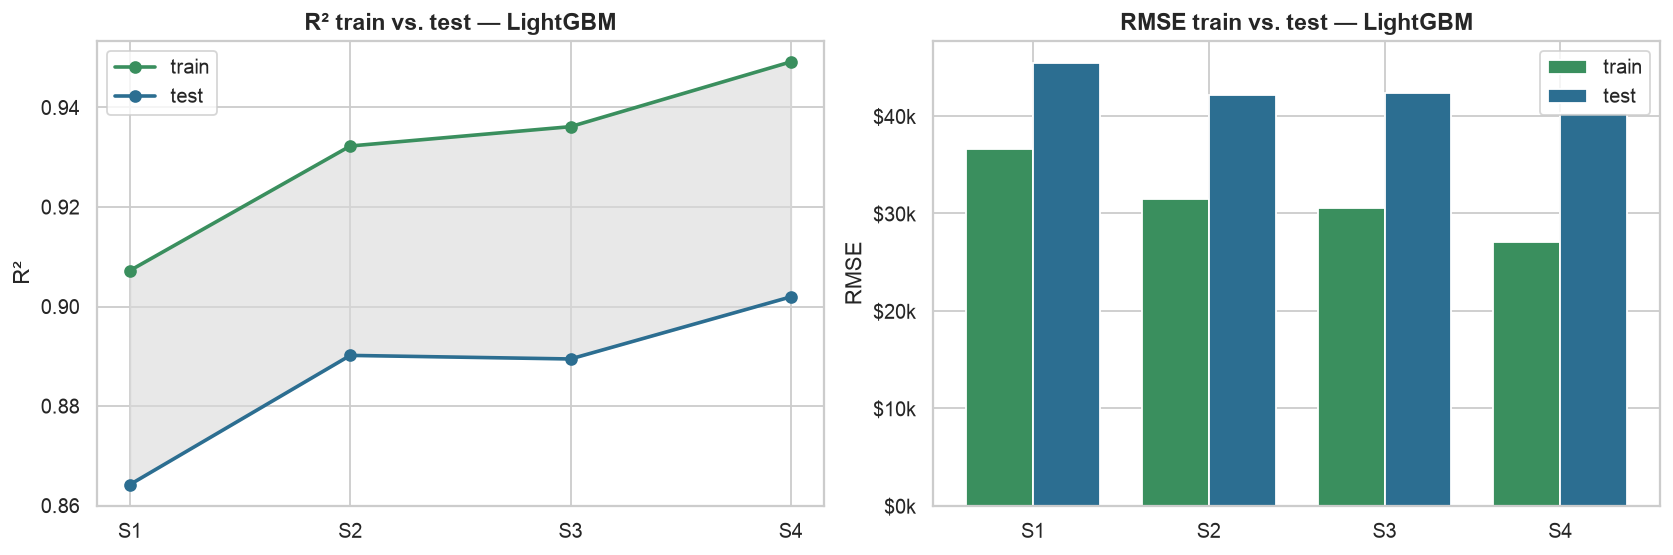

In [6]:
lg_res, lg_oof = {}, {}
for k,cols in escen.items():
    lg_res[k], lg_oof[k] = nested(cols)
tt = pd.DataFrame({k:{"features":len(escen[k]),"R2_train":lg_res[k]["R2_train"],"R2_test":lg_res[k]["R2_test"],
                      "brecha_R2":lg_res[k]["brecha"],"RMSE_train":lg_res[k]["RMSE_train"],
                      "RMSE_test":lg_res[k]["RMSE_test"],"MAPE_test":lg_res[k]["MAPE_test"]} for k in escen}).T
display(tt.round({"features":0,"R2_train":3,"R2_test":3,"brecha_R2":3,"RMSE_train":0,"RMSE_test":0,"MAPE_test":1}))

fig,axs=plt.subplots(1,2,figsize=(13,4.4)); x=np.arange(len(escen))
axs[0].plot(x,tt["R2_train"],"o-",color=ACCENT,lw=2,label="train")
axs[0].plot(x,tt["R2_test"],"o-",color=PAL,lw=2,label="test")
axs[0].fill_between(x,tt["R2_test"],tt["R2_train"],color="0.85",alpha=.6)
axs[0].set(title="R² train vs. test — LightGBM",ylabel="R²",xticks=x); axs[0].set_xticklabels(list(escen)); axs[0].legend()
axs[1].bar(x-0.19,tt["RMSE_train"],0.38,color=ACCENT,label="train"); axs[1].bar(x+0.19,tt["RMSE_test"],0.38,color=PAL,label="test")
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"${v/1e3:.0f}k"))
axs[1].set(title="RMSE train vs. test — LightGBM",ylabel="RMSE",xticks=x); axs[1].set_xticklabels(list(escen)); axs[1].legend()
plt.show()

**Lectura.** El **test** mejora al sumar información y alcanza el mejor valor observado entre los
tres modelos (R² ~0,90; RMSE ~USD 40k; MAPE ~16–17%). Un aspecto a destacar es la **brecha**: la búsqueda
de hiperparámetros selecciona regularización (tasa de aprendizaje baja, submuestreo, mínimo de casos por
hoja, penalización L1/L2), lo que tendería a **reducir la brecha train–test** respecto del Random Forest
(que rondaba ~0,10). El boosting tuneado, entonces, no solo mostraría mejor predicción sino también
**menor sobreajuste**. El aporte por bloques seguiría el patrón conocido —localización y texto con mayor
peso, microlocalización menor—, ahora sobre un modelo que aprovecharía algo más de cada uno.

## 2. Comparación de los tres modelos (cierre de RQ1)

Ponemos lado a lado, en **test** y por escenario, el **hedónico (OLS)**, el **Random Forest** (del
notebook 03) y **LightGBM**. Es el cuadro que responde la pregunta central de la tesis.

,OLS_R2,RF_R2,LGBM_R2,OLS_RMSE,RF_RMSE,LGBM_RMSE,OLS_brecha,RF_brecha,LGBM_brecha
escenario,,,,,,,,,
S1,0.820,0.863,0.864,86121.0,46345.0,45448.0,0.007,0.079,0.043
S2,0.847,0.879,0.890,73285.0,44222.0,42102.0,0.007,0.096,0.042
S3,0.849,0.882,0.889,72649.0,43848.0,42388.0,0.009,0.100,0.047
S4,0.866,0.890,0.902,64571.0,42998.0,40336.0,0.009,0.096,0.047


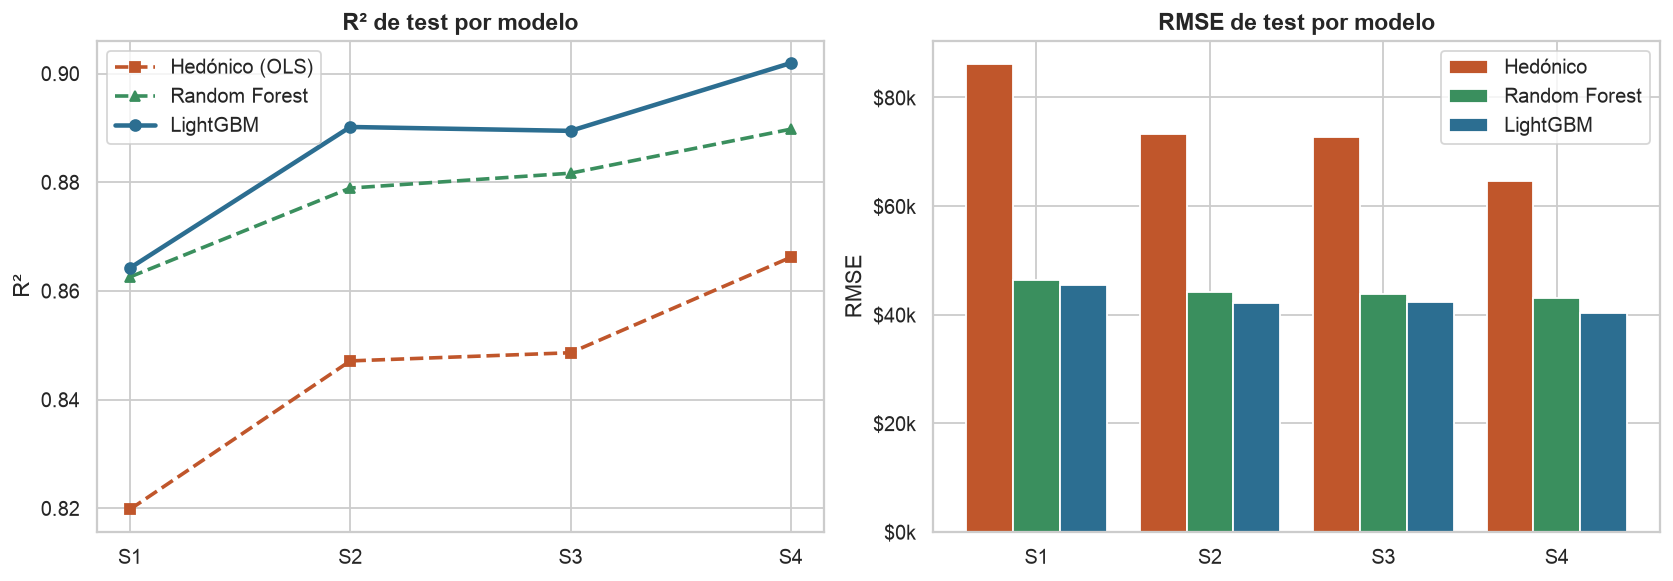

In [7]:
ols_res, ols_oof = {}, {}
for k,cols in escen.items(): ols_res[k], ols_oof[k] = ols_tt(cols)

# Random Forest desde la tabla del notebook 03 (si está disponible)
rf_path = ROOT / "reports" / "tables" / "modelado" / "random_forest_s1_s4.csv"
rf = pd.read_csv(rf_path).set_index("escenario") if rf_path.exists() else None

filas=[]
for k in escen:
    row={"escenario":k,
         "OLS_R2":ols_res[k]["R2_test"], "RF_R2":(rf.loc[k,"R2_test"] if rf is not None else np.nan), "LGBM_R2":lg_res[k]["R2_test"],
         "OLS_RMSE":ols_res[k]["RMSE_test"], "RF_RMSE":(rf.loc[k,"RMSE_test"] if rf is not None else np.nan), "LGBM_RMSE":lg_res[k]["RMSE_test"],
         "OLS_brecha":ols_res[k]["brecha"], "RF_brecha":(rf.loc[k,"brecha_R2"] if rf is not None else np.nan), "LGBM_brecha":lg_res[k]["brecha"]}
    filas.append(row)
comp=pd.DataFrame(filas).set_index("escenario")
display(comp.round({c:(3 if ("R2" in c or "brecha" in c) else 0) for c in comp.columns}))

fig,axs=plt.subplots(1,2,figsize=(13,4.6)); x=np.arange(len(escen)); w=.27
axs[0].plot(x,comp["OLS_R2"],"s--",color=PAL2,lw=2,label="Hedónico (OLS)")
if rf is not None: axs[0].plot(x,comp["RF_R2"],"^--",color=ACCENT,lw=2,label="Random Forest")
axs[0].plot(x,comp["LGBM_R2"],"o-",color=PAL,lw=2.5,label="LightGBM")
axs[0].set(title="R² de test por modelo",ylabel="R²",xticks=x); axs[0].set_xticklabels(list(escen)); axs[0].legend()
axs[1].bar(x-w,comp["OLS_RMSE"],w,color=PAL2,label="Hedónico")
if rf is not None: axs[1].bar(x,comp["RF_RMSE"],w,color=ACCENT,label="Random Forest")
axs[1].bar(x+w,comp["LGBM_RMSE"],w,color=PAL,label="LightGBM")
axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"${v/1e3:.0f}k"))
axs[1].set(title="RMSE de test por modelo",ylabel="RMSE",xticks=x); axs[1].set_xticklabels(list(escen)); axs[1].legend()
plt.show()

**Lectura.** El orden observado coincide con el que anticipa la teoría: **hedónico < Random Forest
≲ LightGBM**. En el escenario completo, LightGBM registra el mejor test (R² ~0,90; RMSE ~USD 40k; MAPE
~16–17%), por encima del Random Forest (~0,89 / ~USD 43k) y muy por encima del hedónico (0,866 / ~USD 65k).
La mejora del boosting sobre el RF sería **real pero acotada** —del orden de un punto de R² y algunos miles
de dólares de RMSE—, lo que sería consistente con que ambos modelos de árboles capturan lo esencial de las
no linealidades y el boosting agrega un ajuste fino. La columna de **brechas** aporta un matiz: LightGBM
combinaría el **mejor test** con una **brecha menor** que el RF, es decir, mejoraría sin mayor
sobreajuste. Frente al salto grande del lineal al primer modelo de árboles, el paso RF→LightGBM luciría
como **rendimientos decrecientes**, lo que sería consistente con que el grueso de la ganancia provendría
de **abandonar la forma lineal** más que de refinar el modelo flexible.

## 3. ¿Dónde gana LightGBM?

Error porcentual (test, escenario S4) por **rango de precio**, comparando LightGBM con el hedónico.

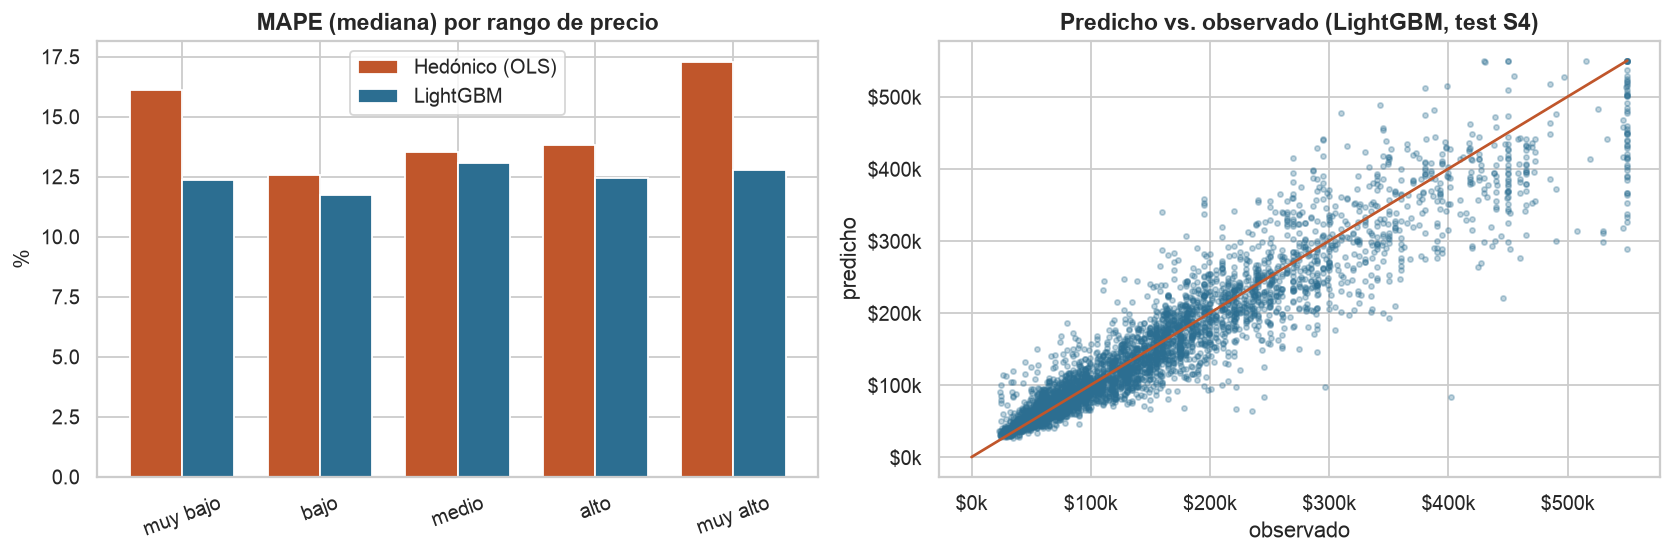

In [8]:
ytu=np.expm1(y)
def ape(o): return np.abs((ytu-np.expm1(o))/ytu)*100
d=pd.DataFrame({"precio":ytu,"ape_lg":ape(lg_oof["S4"]),"ape_ols":ape(ols_oof["S4"])})
d["q"]=pd.qcut(d["precio"],5,labels=["muy bajo","bajo","medio","alto","muy alto"])
g=d.groupby("q")[["ape_ols","ape_lg"]].median()
fig,axs=plt.subplots(1,2,figsize=(13,4.4)); x=np.arange(len(g)); w=.38
axs[0].bar(x-w/2,g["ape_ols"],w,color=PAL2,label="Hedónico (OLS)")
axs[0].bar(x+w/2,g["ape_lg"],w,color=PAL,label="LightGBM")
axs[0].set(title="MAPE (mediana) por rango de precio",ylabel="%",xticks=x); axs[0].set_xticklabels(g.index,rotation=20); axs[0].legend()
lim=np.percentile(ytu,99)
axs[1].scatter(ytu.clip(0,lim),np.expm1(lg_oof["S4"]).clip(0,lim),s=8,alpha=.3,color=PAL)
axs[1].plot([0,lim],[0,lim],color=PAL2,lw=1.5)
axs[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"${v/1e3:.0f}k")); axs[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_:f"${v/1e3:.0f}k"))
axs[1].set(title="Predicho vs. observado (LightGBM, test S4)",xlabel="observado",ylabel="predicho")
plt.show()

**Lectura.** Como el RF, LightGBM mejora en todos los rangos y sobre todo en los **extremos de
precio**, donde el lineal era más flojo. La nube predicho-vs-observado se ajusta bien a la diagonal en
casi todo el rango; las propiedades más caras siguen siendo las más difíciles —son pocas y muy
heterogéneas—, pero el error se contiene mejor que con el hedónico.

## 4. Importancia de variables

Combinamos la importancia por **ganancia** (cuánto mejora la pérdida cada variable en los cortes, nativa
de LightGBM) con la de **permutación** (más comparable entre modelos), y ordenamos por esta última.

Hiperparámetros del modelo final: {'colsample_bytree': np.float64(0.8604), 'learning_rate': np.float64(0.0117), 'max_depth': 10, 'min_child_samples': 34, 'n_estimators': 1105, 'num_leaves': 16, 'reg_alpha': np.float64(0.0061), 'reg_lambda': np.float64(0.0061), 'subsample': np.float64(0.7217)}


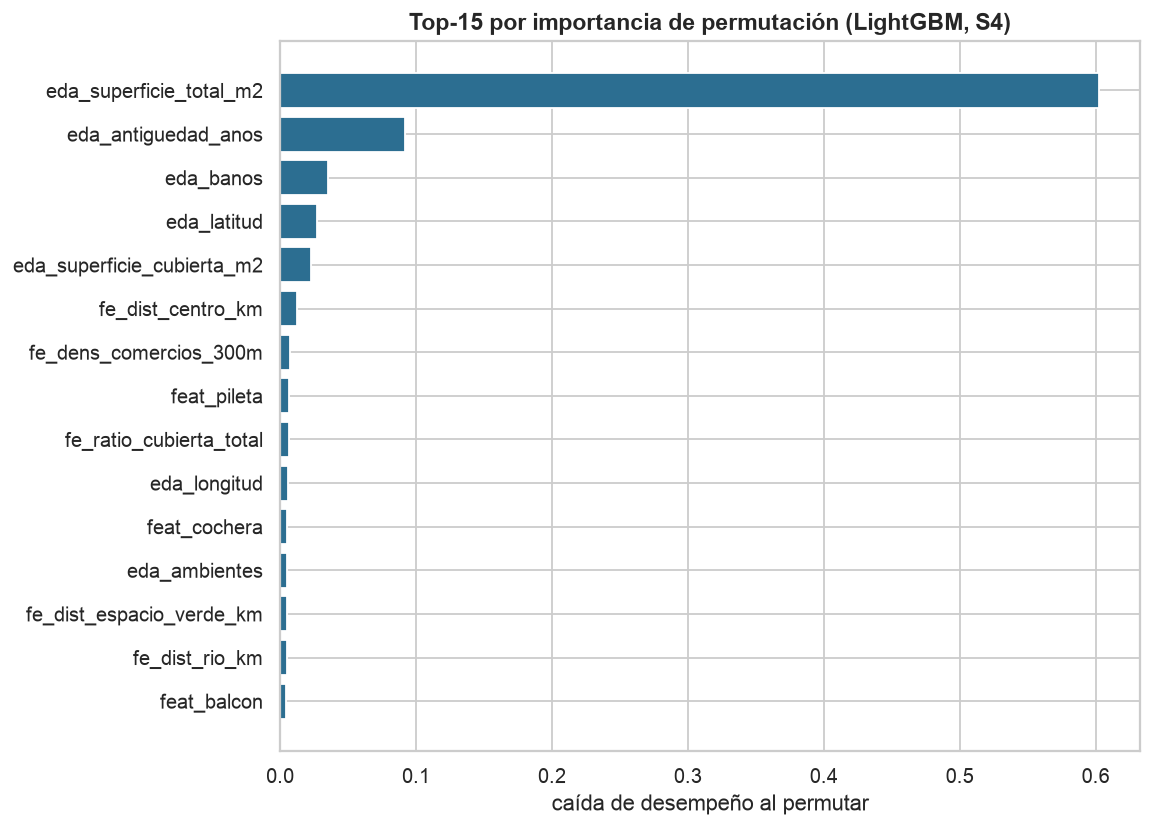

,variable,ganancia,permutacion
0,eda_superficie_total_m2,0.6262,0.6026
1,eda_antiguedad_anos,0.0670,0.0919
2,eda_banos,0.1170,0.0350
3,eda_latitud,0.0199,0.0273
4,eda_superficie_cubierta_m2,0.0536,0.0228
5,fe_dist_centro_km,0.0105,0.0127
6,fe_dens_comercios_300m,0.0063,0.0073
7,feat_pileta,0.0113,0.0067
8,fe_ratio_cubierta_total,0.0053,0.0067
9,eda_longitud,0.0069,0.0061


In [9]:
base=Pipeline([("prep",prep_oh(escen["S4"])),("m",lgbm())])
rs=RandomizedSearchCV(base,DIST,n_iter=N_ITER,cv=GroupKFold(5),scoring="neg_mean_squared_error",random_state=SEED,n_jobs=-1).fit(df[escen["S4"]],y,groups=groups)
final=rs.best_estimator_; print("Hiperparámetros del modelo final:",{k.split('__')[1]:(round(v,4) if isinstance(v,float) else v) for k,v in rs.best_params_.items()})
names=[n.split("__",1)[-1] for n in final.named_steps["prep"].get_feature_names_out()]
gain=final.named_steps["m"].booster_.feature_importance(importance_type="gain"); gain=gain/gain.sum()
Xt=final.named_steps["prep"].transform(df[escen["S4"]])
perm=permutation_importance(final.named_steps["m"],Xt,y,n_repeats=5,random_state=SEED,n_jobs=-1)
imp=pd.DataFrame({"variable":names,"ganancia":gain,"permutacion":perm.importances_mean}).sort_values("permutacion",ascending=False)
top=imp.head(15)
fig,ax=plt.subplots(figsize=(9,6.5))
ax.barh(top["variable"][::-1],top["permutacion"][::-1],color=PAL)
ax.set(title="Top-15 por importancia de permutación (LightGBM, S4)",xlabel="caída de desempeño al permutar")
plt.show()
display(imp.head(12).round(4).reset_index(drop=True))

**Lectura.** El ranking vuelve a ser **coherente** con el hedónico, el Lasso y el Random Forest: la
**superficie** manda, seguida de antigüedad, superficie cubierta, baños y ambientes, con localización
(latitud) y algunos atributos de texto (cochera, pileta) más abajo. Que **cuatro enfoques distintos**
—coeficientes OLS, encogimiento Lasso, importancia RF e importancia LightGBM— coincidan en los
protagonistas es la mejor evidencia de que el modelo lee **señal real** y no artefactos. La
microlocalización aparece con peso bajo, coherente con su aporte modesto en todos los modelos.

## 5. Conclusiones

- **RQ1, cierre.** El orden de desempeño en test ordena los modelos como **hedónico < Random Forest ≲
  LightGBM**. LightGBM sería el modelo de **mejor desempeño** (en esta muestra): R² ~0,90, RMSE ~USD 40k y
  MAPE ~16–17% en el escenario completo, sobre las mismas particiones y con CV anidada. La diferencia de
  los árboles frente al lineal es amplia; la de LightGBM sobre el RF sería **acotada** (rendimientos
  decrecientes), lo que sería consistente con que el grueso de la mejora provendría de **dejar la forma
  lineal** más que del ajuste fino del boosting.
- **Sobreajuste.** La búsqueda de hiperparámetros dotaría a LightGBM de una **brecha train–test menor**
  que la del RF: mejoraría en test **sin** mayor sobreajuste, lo que sugeriría el equilibrio
  sesgo–varianza más favorable de los tres en este problema.
- **De dónde y dónde.** El aporte incremental se concentraría en **localización** y **texto**; la ventaja
  frente al lineal tendería a ampliarse en los **extremos de precio**.
- **Explicabilidad.** La importancia de variables resultaría coherente con la de los otros tres modelos:
  superficie, antigüedad, baños, ambientes y localización como columna vertebral del precio. La
  interpretación local —cómo se arma cada tasación— se abordará con **SHAP** en la etapa de
  interpretabilidad (RQ5).
- **Próximos pasos.** Con el modelo de mejor desempeño seleccionado, seguirían el **diagnóstico espacial**
  de los residuos (Moran's I) y el *spatial lag* por fold (RQ3–RQ4), y la **interpretabilidad** con SHAP
  (RQ5).

## Referencias

**Libros**

- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning* (2ª ed.), cap. 10. Springer.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2ª ed.), cap. 8. Springer.
- Kuhn, M., & Johnson, K. (2013). *Applied Predictive Modeling*. Springer.
- Molnar, C. (2022). *Interpretable Machine Learning* (2ª ed.). — importancia por permutación.

**Artículos**

- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics, 29*(5), 1189–1232.
- Ke, G., et al. (2017). LightGBM: a highly efficient gradient boosting decision tree. *NeurIPS 30*.
- Chen, T., & Guestrin, C. (2016). XGBoost: a scalable tree boosting system. *KDD*.
- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *JMLR, 13*, 281–305.
- Gutiérrez et al. (2026); Tapia et al. (2025); Gyger et al. (2026) — antecedentes AVM.